<a href="https://colab.research.google.com/github/bvsvntv/ai-ml-learning/blob/main/notebooks/lang-graph/review_reply_workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [69]:
!pip install -U langchain-openai

In [70]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from google.colab import userdata
from pydantic import BaseModel, Field
from typing import TypedDict, Literal
from IPython.display import Image

In [71]:
apiKey = userdata.get('OPENAI_API_KEY')
model = ChatOpenAI(api_key = apiKey, model = "gpt-6-luna")

In [72]:
class SentimentSchema(BaseModel):
  sentiment: Literal["positive", "negative"] = Field("Sentiment fo the review")

In [73]:
class DiagnosisSchema(BaseModel):
  issue_type: Literal["UX", "Performance", "Bug", "Support", "Other"] = Field(description="The category of issue mentioned in the review.")
  tone: Literal["angry", "frustrated", "dissapointed", "calm"] = Field(description="The emotional tone expressed by the user.")
  urgency: Literal["low", "medium", "high"] = Field(description="How urgent or critical the issue appears to be.")

In [74]:
structured_model = model.with_structured_output(SentimentSchema)
structured_model2 = model.with_structured_output(DiagnosisSchema)

In [75]:
# prompt = f"What is the sentiment of the following review - The UI/UX is excellent."
# result = structured_model.invoke(prompt)
# print(result.sentiment)

In [76]:
class ReviewState(TypedDict):
  review: str
  sentiment: Literal["positive", "negative"]
  diagnosis: dict
  response: str

In [77]:
def find_sentiment(state: ReviewState):
  prompt = f"For the following review find out the sentiment. \n {state["review"]}"

  sentiment = structured_model.invoke(prompt).sentiment

  return {"sentiment": sentiment}

In [85]:
def diagnosis_review(state: ReviewState):
  prompt = f"""Diagnose this negative review:\n\n{state["review"]}\n
  Return issue_type, tone and urgency.
  """

  response = structured_model2.invoke(prompt)
  return {"diagnosis": response.model_dump()}

In [79]:
def positive_response(state: ReviewState):
  prompt = f"""Write a warm thank-you message in response to this review:
  \n\n{state["review"]}\n
  Also, kindly ask the user to leave feedback on our website.
  """

  response = model.invoke(prompt).content
  return {"response": response}

In [80]:
def negative_response(state: ReviewState):
  diagnosis = state["diagnosis"]

  prompt = f"""You are a support assistant.
  The user had a '{diagnosis["issue_type"]}' issue, sounded '{diagnosis["tone"]}', and marked urgency as '{diagnosis["urgency"]}'.
  Write an empathetic, helpful resolution message.
  """

  response = model.invoke(prompt).content

  return {"response": response}

In [81]:
def check_sentiment(state: ReviewState) -> Literal["positive_response", "diagnosis_review"]:
  if state["sentiment"] == "positive":
    return "positive_response"
  else:
    return "diagnosis_review"


In [82]:
# graph
graph = StateGraph(ReviewState)

graph.add_node("find_sentiment", find_sentiment)
graph.add_node("diagnosis_review", diagnosis_review)
graph.add_node("positive_response", positive_response)
graph.add_node("negative_response", negative_response)

graph.add_edge(START, "find_sentiment")
graph.add_conditional_edges("find_sentiment", check_sentiment)
graph.add_edge("diagnosis_review", "negative_response")
graph.add_edge("positive_response", END)
graph.add_edge("negative_response", END)

workflow = graph.compile()

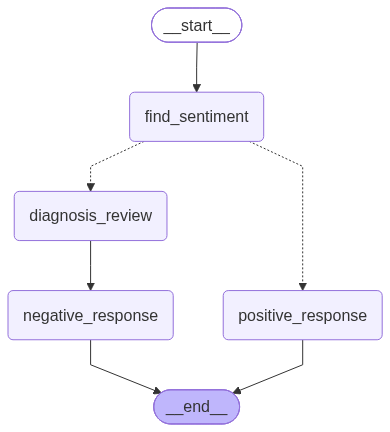

In [83]:
Image(workflow.get_graph().draw_mermaid_png())

In [86]:
intial_state={
    'review': "I’ve been trying to log in for over an hour now, and the app keeps freezing on the authentication screen. I even tried reinstalling it, but no luck. This kind of bug is unacceptable, especially when it affects basic functionality."
}

workflow.invoke(intial_state)

issue_type='Bug' tone='frustrated' urgency='high'


{'review': 'I’ve been trying to log in for over an hour now, and the app keeps freezing on the authentication screen. I even tried reinstalling it, but no luck. This kind of bug is unacceptable, especially when it affects basic functionality.',
 'sentiment': 'negative',
 'diagnosis': {'issue_type': 'Bug', 'tone': 'frustrated', 'urgency': 'high'},
 'response': 'I’m sorry you’re running into this bug, especially with it affecting something urgent. I understand how frustrating that is. We’re treating it as a priority and will work to identify the cause and get it resolved as quickly as possible. If you can share the steps that trigger the issue, any error message, and what you expected to happen, that will help us narrow it down faster.'}